# New Lab03 — 02. Binary sentiment modeling với Hugging Face

Mặc định **MODE="train"**, **DEVICE="cuda"** để train từ pretrained base trên Kaggle GPU; chạy từ trên xuống. Đổi **MODE="view"** nếu chỉ muốn đọc kết quả đã lưu. Local dùng cùng notebook/module, chọn CPU hoặc CUDA phù hợp. Notebook bao gồm pretrained sentiment, baseline TF-IDF và DistilBERT regularized; huấn luyện **tối đa 3 epoch với early stopping**.

| Phase | Nội dung | Module/file tham chiếu | Artifact trong outputs/ |
|---|---|---|---|
| 1 | Setup, environment và sanity tests | `src/notebook_runtime.py`, `tests/` | preflight log/XML |
| 2 | Pretrained sentiment / tokenization | `src/models/classifier.py`, `scripts/run_exercise1.py` | predictions, tokens/IDs/mask, comparison PNG |
| 3 | Architecture, optimizer, regularization | `config/frozen_trial.json`, `src/training/frozen.py` | config, optimizer groups, architecture |
| 4 | Baseline + fine-tuning | `scripts/run_frozen_trial.py`, `src/training/trainer.py` | epoch_history, learning_curves |
| 5 | Accuracy/loss và time/RAM/VRAM | `src/performance.py` | performance PNG/JSON, resource_history |
| 6 | Validation checkpoint / threshold sweep | `src/training/thresholds.py` | frozen policy, 19-point scan |
| 7 | Test và calibration | `src/training/metrics.py` | confusion, metrics bar, ROC/PR, reliability |
| 8 | Error analysis | `src/study.py`, `src/utils/plots.py` | samples, threshold_errors |
| 9 | Save/load, publish và ZIP | `src/utils/runs.py`, `scripts/publish_artifacts.py` | log, catalog, SHA256, review/checkpoint ZIP |

Dữ liệu và feature engineering được giải thích trong [notebook01](01_eda_preprocessing_feature_engineering.ipynb). Các bảng/ảnh bên dưới đọc artifact của chính phiên thực thi; không ghi trước accuracy hoặc selected epoch. MODE=view dùng outputs/latest_report.json sau khi đã có kết quả.

**Kết quả đã lưu**: run `20261104T110654Z_frozen_trial_00eccdd1` hoàn thành3/3epoch, chọn checkpoint epoch3 và validation threshold0,5. Test accuracy82,18%, Binary F182,11%. Output dưới đây được render ở MODE=view từ chính artifact run này; không phải một lượt train thêm. Source vẫn mặc định train/cuda để chạy mới; đổi MODE=view nếu chỉ đọc report.

## 1. Setup và preflight

Kaggle: bật GPU và Internet. Python3.12 riêng tránh xung đột thư viện kernel. Local cần cài requirements trước khi mở notebook; chọn `DEVICE="cpu"` nếu chủ động dùng CPU. Không train full mạng neural trong bước kiểm thử: preflight dùng tiny fixtures, sanity overfit một minibatch và kiểm tra early stopping/threshold/reload/artifact.

Run All theo thứ tự để các biến session/config và helper luôn được định nghĩa.

In [1]:
from pathlib import Path
import subprocess, sys, json
MODE = "train"
DEVICE = "cuda"
REPO_URL = "https://github.com/lacthui06/Lab-DL.git"
REPO_REF = "new-lab03"
PROFILE = Path("labs/new-lab03/config/frozen_trial.json")
start = Path.cwd().resolve()
REPO = next((p for p in (start,*start.parents) if (p/PROFILE).is_file()), None)
KAGGLE_WORKING = Path("/kaggle/working")
if REPO is None and KAGGLE_WORKING.is_dir():
    REPO = KAGGLE_WORKING/"Lab-DL-new-lab03"
    if REPO.exists() and not (REPO/PROFILE).is_file():
        import uuid
        REPO = KAGGLE_WORKING/("Lab-DL-new-lab03-"+uuid.uuid4().hex[:8])
    if not REPO.exists():
        subprocess.run(["git","clone","--depth","1","--branch",REPO_REF,"--single-branch",REPO_URL,str(REPO)],check=True)
assert REPO is not None, "Mở notebook trong repository hoặc trên Kaggle."
if not (REPO/PROFILE).is_file():
    raise FileNotFoundError(f"Thiếu {PROFILE} trong {REPO}; kiểm tra source trên nhánh new-lab03.")
print("Source repository:", REPO)
profile = json.loads((REPO/"labs/new-lab03/config/frozen_trial.json").read_text())["exercise2"]
assert profile["num_train_epochs"] == 3 and profile.get("early_stopping", {}).get("enabled"), "Cập nhật source branch new-lab03 cho đúng profile của notebook trước khi chạy."
sys.path.insert(0,str(REPO/"labs/new-lab03"))
from src.notebook_runtime import NotebookSession
session = NotebookSession(REPO, MODE, DEVICE)
assert "LAB03_SESSION_ID" in session.env, "Source repository chưa đồng bộ với notebook; cập nhật branch new-lab03 và mở session Kaggle mới."
session.setup()
from IPython.display import display


Source repository: /workspace/Lab-DL-new-lab03
MODE=view: đọc artifacts đã lưu; không cài/tải model, không training.


In [2]:
# Tách môi trường kiểm thử, giữ session ID cho các bước training/artifact.
saved_session_id = session.env.pop("LAB03_SESSION_ID", None)
try:
    session.preflight()
finally:
    if saved_session_id is not None:
        session.env["LAB03_SESSION_ID"] = saved_session_id


View mode: dùng bằng chứng đã lưu; không chạy lại tests hoặc training.


## Kiến trúc chi tiết của hai model (text)

In toàn bộ module tree và số tham số trước inference/training. Exercise1: pretrained SST-2 inference; Exercise2: base model và head nhị phân. MODE=view dựng cấu trúc khai báo offline, không reload weights; MODE=train đọc config đúng revision trên Hub. Text lưu trong `outputs/architecture/model_architectures.txt`.

Bảng tóm tắt phân biệt requires_grad parameters và weights thực sự tối ưu: Exercise1 chỉ inference nên không có weights được tối ưu. Module tree là cấu trúc từ config đã pin, không phải phép reload weights của run.

In [3]:
session.architectures()

,model,name,input,output,layers,hidden,total_parameters,requires_grad_parameters,parameters_optimized_in_this_lab
0,exercise1,distilbert/distilbert-base-uncased-finetuned-s...,"[B,L], L<=128","[B,2] logits",6,768,66955010,66955010,0
1,exercise2,distilbert/distilbert-base-uncased,"[B,L], L<=128","[B,2] logits",6,768,66955010,14767874,14767874


exercise1: distilbert/distilbert-base-uncased-finetuned-sst-2-english
pretrained SST-2 inference; no optimization in this lab
Architecture from pinned Hugging Face config; weights are loaded later by training/inference.
Total parameters: 66,955,010; requires_grad parameters: 66,955,010
DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSdpaAttention(
            (dropout): Dropout(p=0.1, inplace=False)
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_

PosixPath('/workspace/Lab-DL-new-lab03/labs/new-lab03/outputs/architecture/model_architectures.txt')

## 2. Exercise1 — Pretrained sentiment và tokenization

Dùng sentiment model đã fine-tune SST-2 cho inference. Pipeline và manual forward/softmax phải cho cùng nhãn/xác suất trong tolerance; xem tokens, input IDs và attention mask. Confidence là xác suất theo mô hình, không bảo đảm đúng trong mọi ngữ cảnh. Exercise2 dùng **DistilBERT base + classification head mới**, không dùng sentiment checkpoint SST-2 để fine-tune.

,text,tokens,input_ids,attention_mask
0,I love this wonderful movie!,"[[CLS], i, love, this, wonderful, movie, !, [S...","[101, 1045, 2293, 2023, 6919, 3185, 999, 102]","[1, 1, 1, 1, 1, 1, 1, 1]"


,text,label,score,probabilities
0,I love this wonderful movie!,POSITIVE,0.999878,"[0.0001224386360263452, 0.9998775720596313]"
1,This movie was terrible and boring.,NEGATIVE,0.999768,"[0.9997683167457581, 0.00023167315521277487]"
2,"The acting was good, but the story was disappo...",NEGATIVE,0.996749,"[0.9967492818832397, 0.0032507420983165503]"


**tokenizer_table.png**

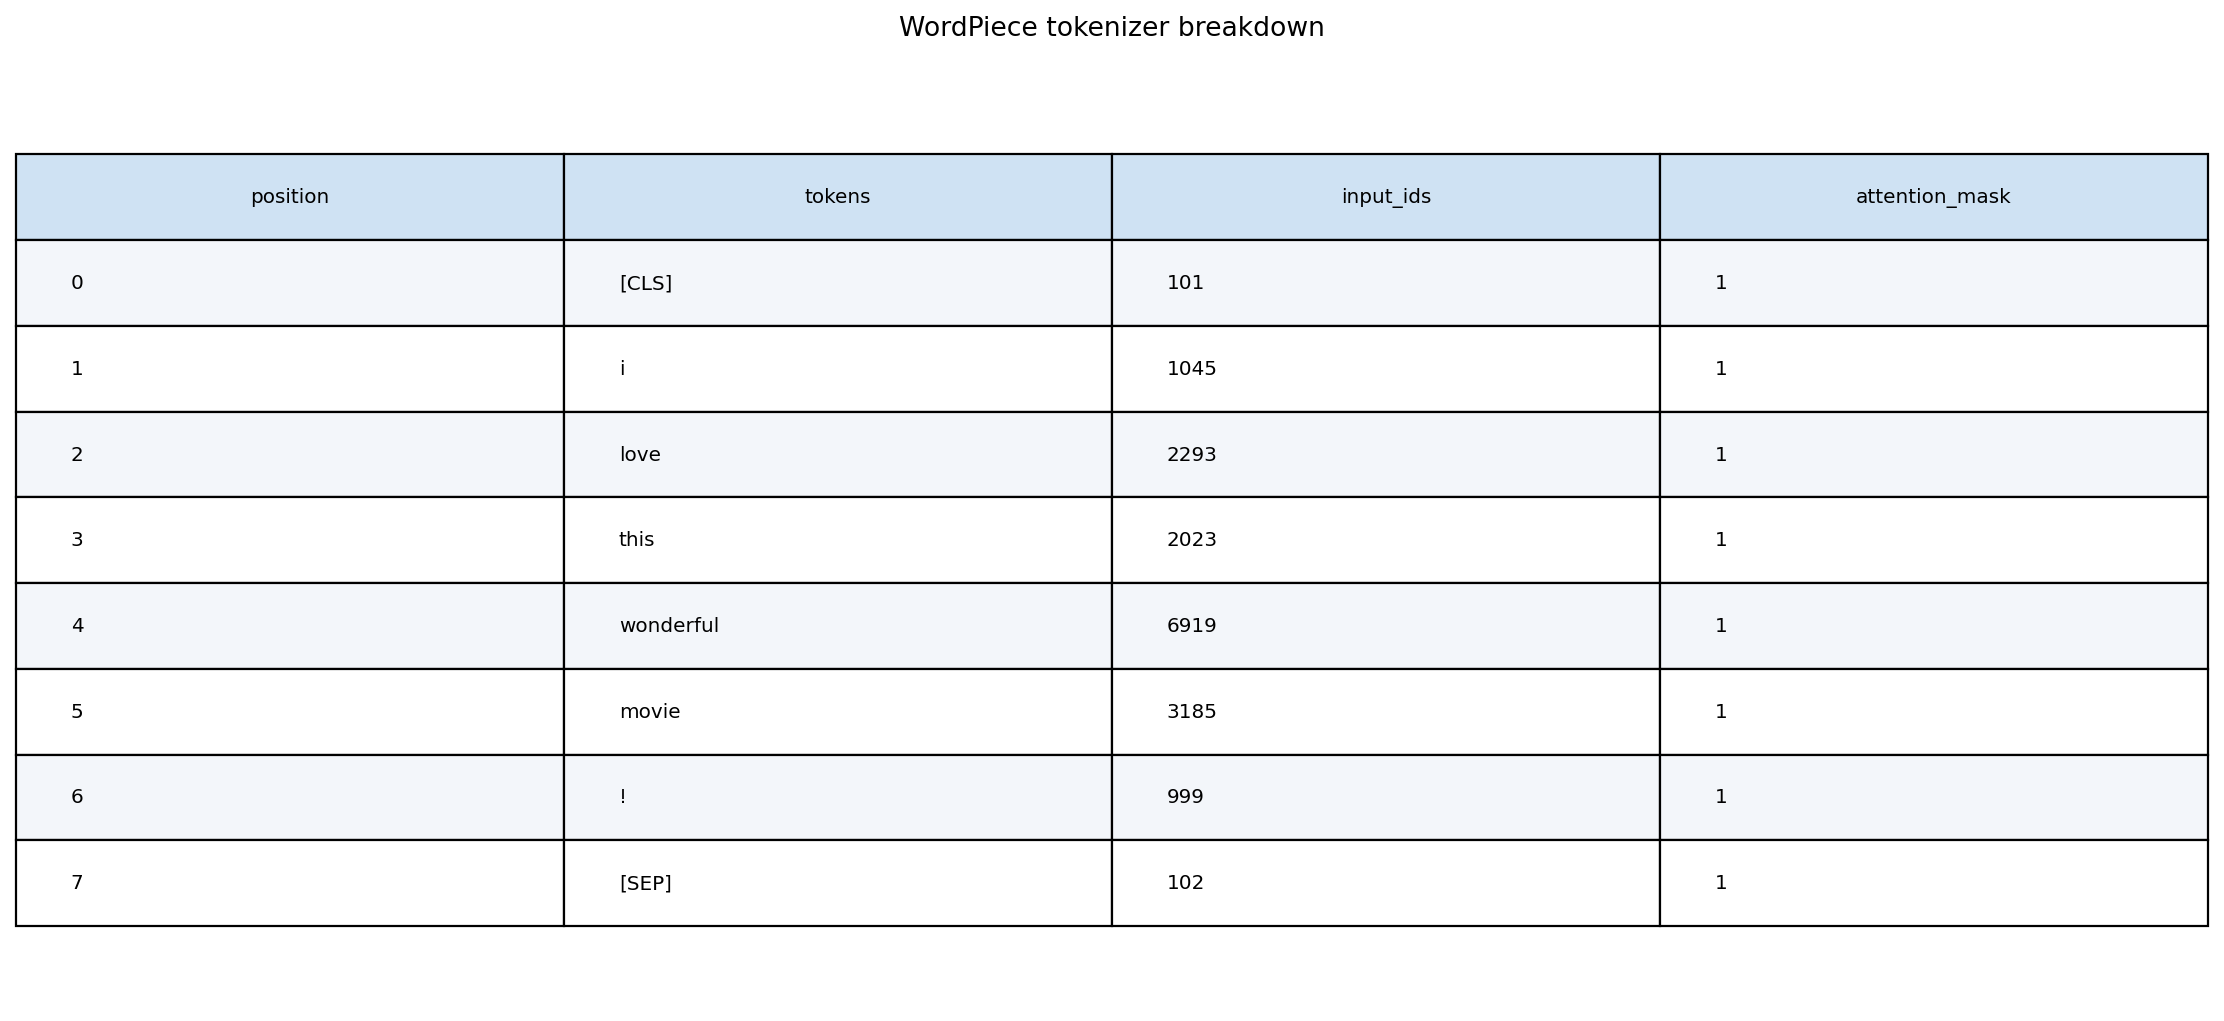

**sentiment_predictions.png**

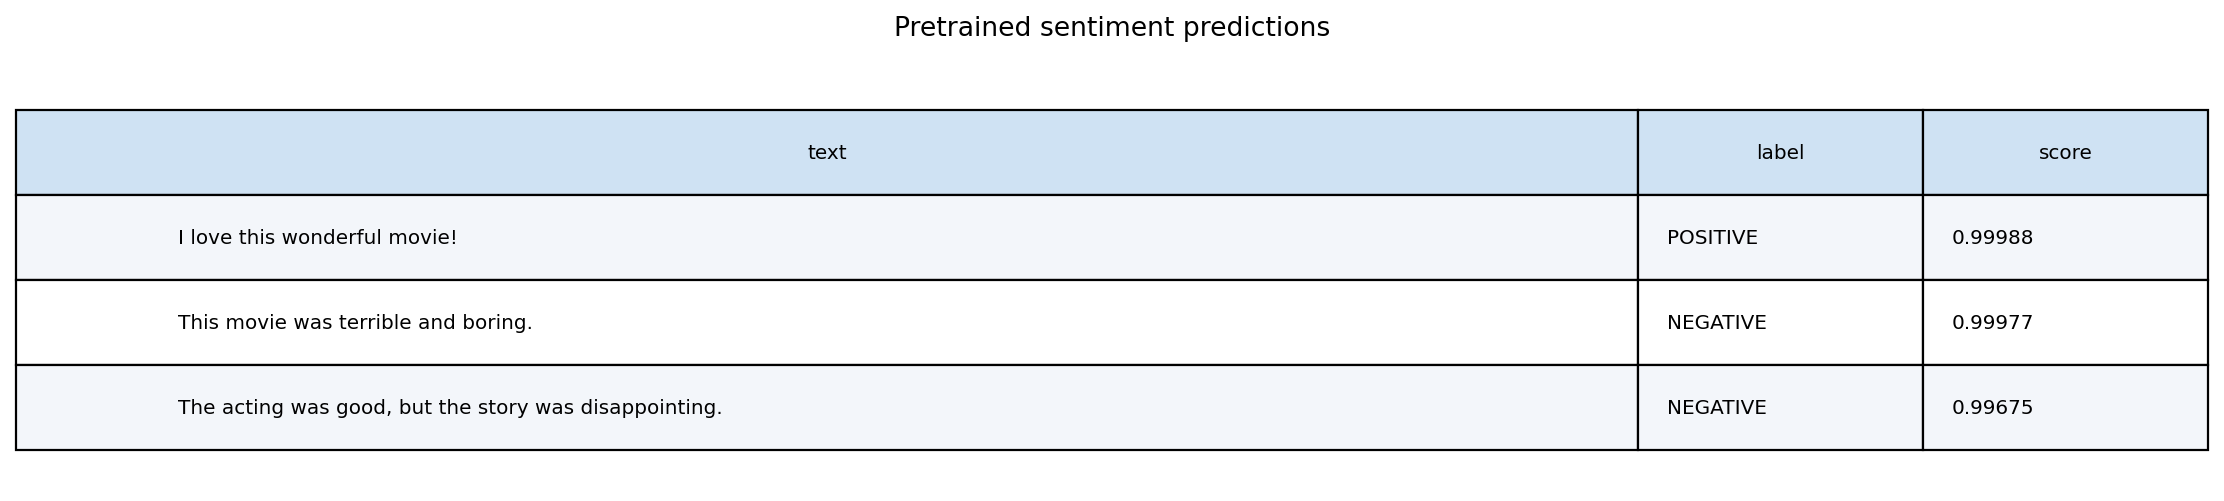

**pipeline_manual_comparison.png**

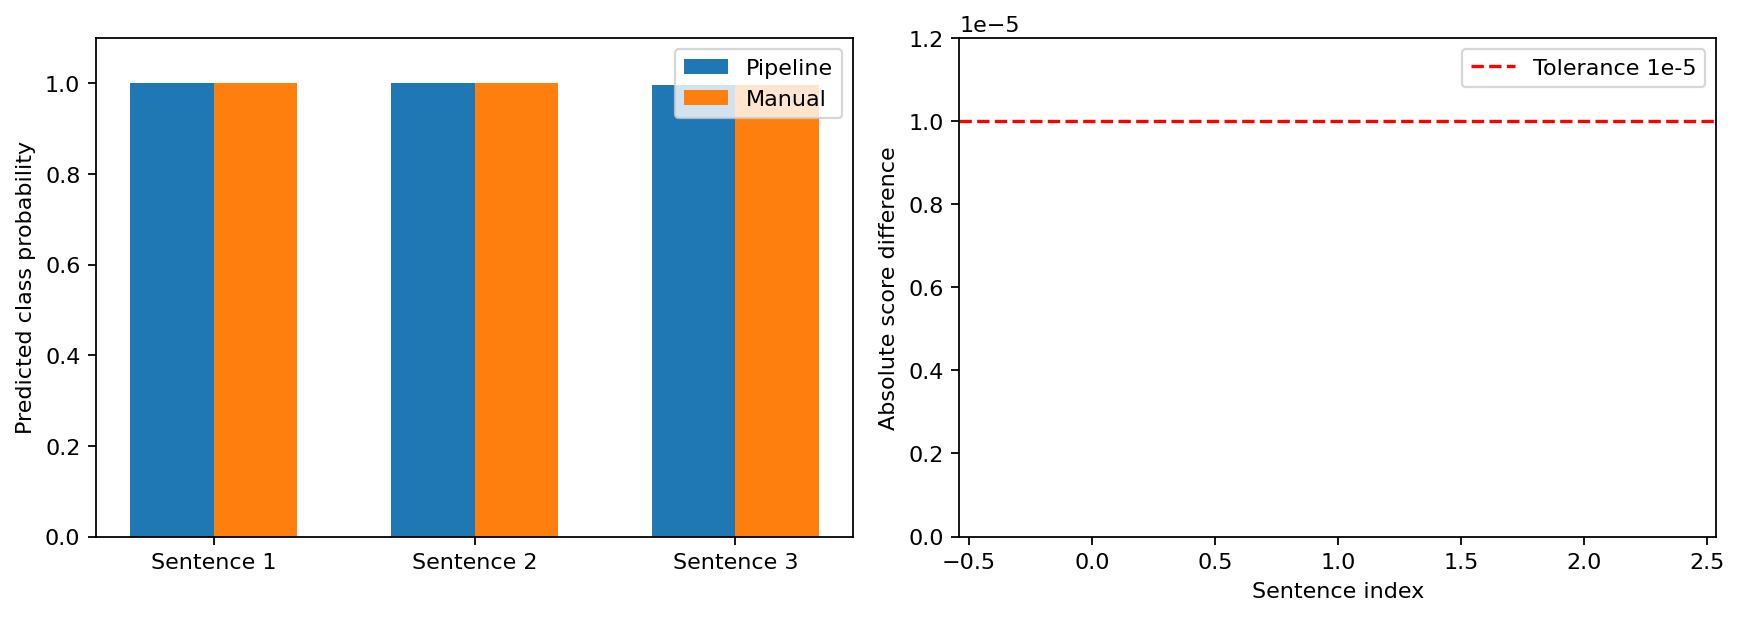

[PosixPath('/workspace/Lab-DL-new-lab03/labs/new-lab03/outputs/runs/20261104T110646Z_exercise1_analysis_a061550c/tokenizer_table.png'),
 PosixPath('/workspace/Lab-DL-new-lab03/labs/new-lab03/outputs/runs/20261104T110646Z_exercise1_analysis_a061550c/sentiment_predictions.png'),
 PosixPath('/workspace/Lab-DL-new-lab03/labs/new-lab03/outputs/runs/20261104T110646Z_exercise1_analysis_a061550c/pipeline_manual_comparison.png')]

In [4]:
session.exercise1()
display(session.table("exercise1_current", "tokenizer_breakdown.json"))
display(session.table("exercise1_current", "predictions.json", "manual"))
session.show("exercise1_visuals", ["tokenizer_table.png", "sentiment_predictions.png", "pipeline_manual_comparison.png"])


## 3. Architecture và cấu hình

Input IDs/mask `[B,L]` → WordPiece/position embedding →6 Transformer blocks → `[CLS]` vector → Linear768/ReLU → dropout0.4 → Linear2 logits. Hidden768, attention12heads, FFN3072. Train bằng cross-entropy trên logits; inference dùng softmax rồi threshold Positive.

Chọn DistilBERT để tận dụng pretrained representation với corpus nhỏ và ngân sách T4. Freeze embedding và4blocks đầu, chỉ học2blocks cuối +head. TF-IDF unigram/bigram + Logistic Regression là baseline đơn giản để kiểm tra Transformer có mang lại lợi ích không; không nối sparse features vào head.

Regularization: dropout encoder/attention0.2, head0.4; AdamW decay0.1 cho weights>=2D, không decay bias/LayerNorm; clipping1; warmup10% rồi linear decay. EncoderLR5e-6, headLR2e-5 vì head khởi tạo mới. Augmentation chỉ từ train, giới hạn25%, chặn trùng/câu có phủ định-tương phản và cân bằng variants.

Tối đa 3 epoch, early stopping theo validation loss, patience2/min_delta0.001. Đây là thiết kế định trước cần kiểm chứng bằng kết quả, không bảo đảm tối ưu tuyệt đối hoặc không overfit.

In [5]:
config = session.read(session.lab/"config/frozen_trial.json")
display(config["exercise2"])
display(config["exercise2"]["early_stopping"])


{'dataset_name': 'cornell-movie-review-data/rotten_tomatoes',
 'dataset_revision': 'aa13bc287fa6fcab6daf52f0dfb9994269ffea28',
 'model_name': 'distilbert/distilbert-base-uncased',
 'model_revision': '12040accade4e8a0f71eabdb258fecc2e7e948be',
 'max_length': 128,
 'batch_size': 16,
 'eval_batch_size': 32,
 'learning_rate': 5e-06,
 'num_train_epochs': 3,
 'weight_decay': 0.1,
 'warmup_ratio': 0.1,
 'fp16': True,
 'threshold_selection': {'enabled': True,
  'selection_metric': 'macro_f1',
  'split': 'validation',
  'grid': '0.05 to 0.95, step 0.05',
  'tie_break': 'closest to 0.5, then smaller threshold'},
 'eval_strategy': 'epoch',
 'eval_steps': 100,
 'logging_steps': 25,
 'metric_for_best_model': 'loss',
 'gradient_accumulation_steps': 1,
 'max_grad_norm': 1.0,
 'dataloader_num_workers': 0,
 'save_only_model': True,
 'epoch_console_summary': True,
 'model_overrides': {'dropout': 0.2,
  'attention_dropout': 0.2,
  'seq_classif_dropout': 0.4},
 'augmentation': {'enabled': True, 'max_ratio

{'enabled': True,
 'patience': 2,
 'min_delta': 0.001,
 'monitor': 'validation_loss'}

## 4. Baseline và fine-tuning tối đa 3 epoch

Pipeline tải official8.530/1.066/1.066 splits, kiểm dữ liệu, tạo augmented train rồi fit TF-IDF baseline train-only. Chọn C∈{0.1,1,10} bằng validation Macro-F1. Transformer khởi tạo từ pretrained base, không resume một model đã fine-tune.

Mỗi epoch đo **full effective train và full validation trong eval mode**. Accuracy/loss end-epoch khác optimization loss chịu dropout lúc training. Early stopping chỉ đếm validation evaluations; evaluate(train) không làm tăng patience. Nếu dừng trước5 thì biểu đồ có đúng số điểm đã chạy. TrụcX là epoch; step để định danh optimizer update/checkpoint.

Checkpoint được chọn theo min validation loss thực tế. Min_delta điều khiển patience, không đổi tiêu chí checkpoint.

View mode: đọc kết quả được chọn trong outputs/latest_report.json.
Run: 20261104T110654Z_frozen_trial_00eccdd1


,epoch,step,train_loss_eval,train_accuracy,validation_loss,validation_accuracy,validation_macro_f1,learning_rate,epoch_runtime_seconds
0,1,551,0.390423,0.823603,0.394246,0.829268,0.829196,3.708810e-06,20.210988
1,2,1102,0.372226,0.834848,0.380126,0.830206,0.830127,1.859449e-06,19.769689
2,3,1653,0.369313,0.835984,0.377385,0.834897,0.834876,6.724950e-09,20.322734


**learning_curves.png**

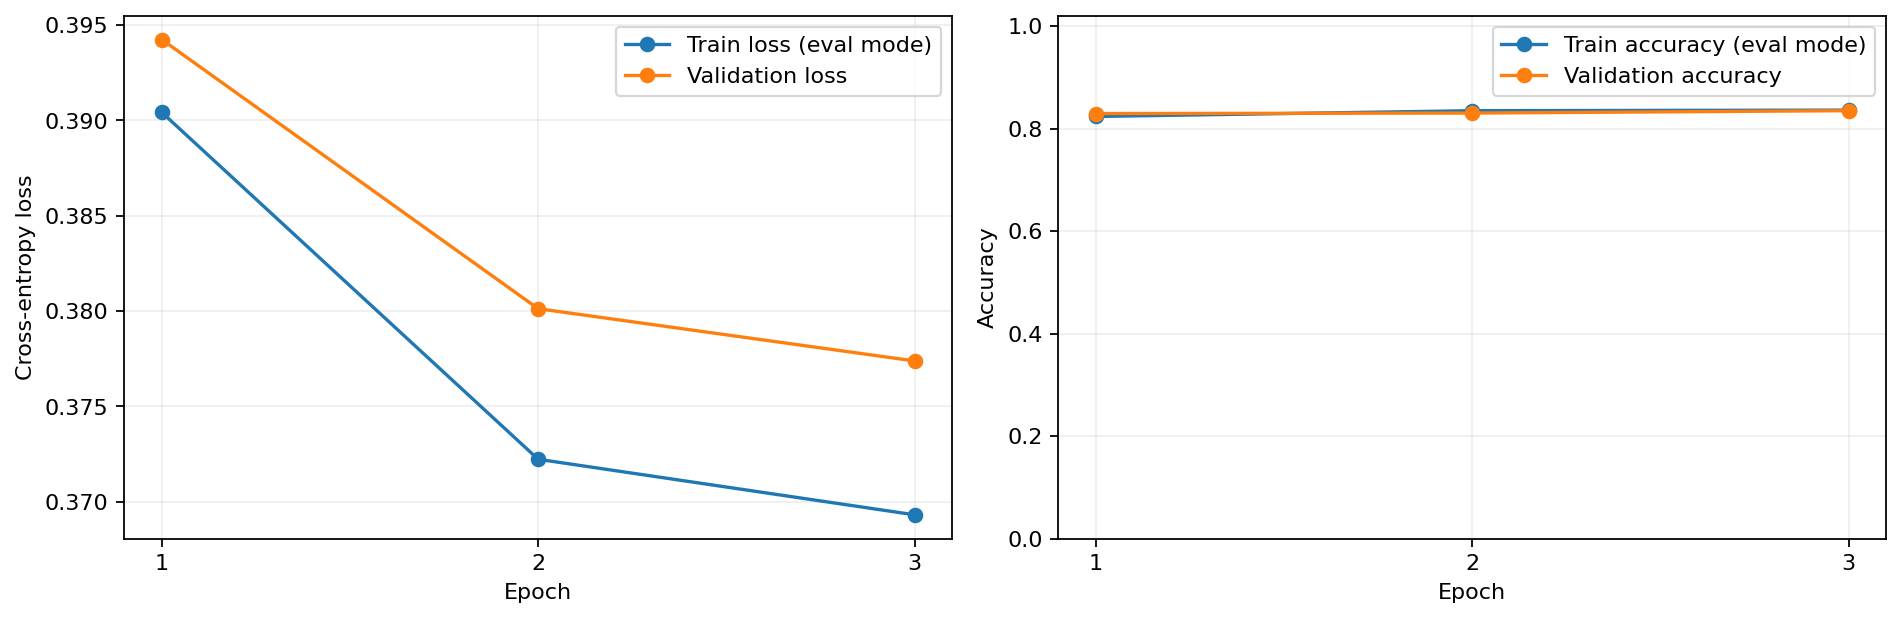

**learning_detail.png**

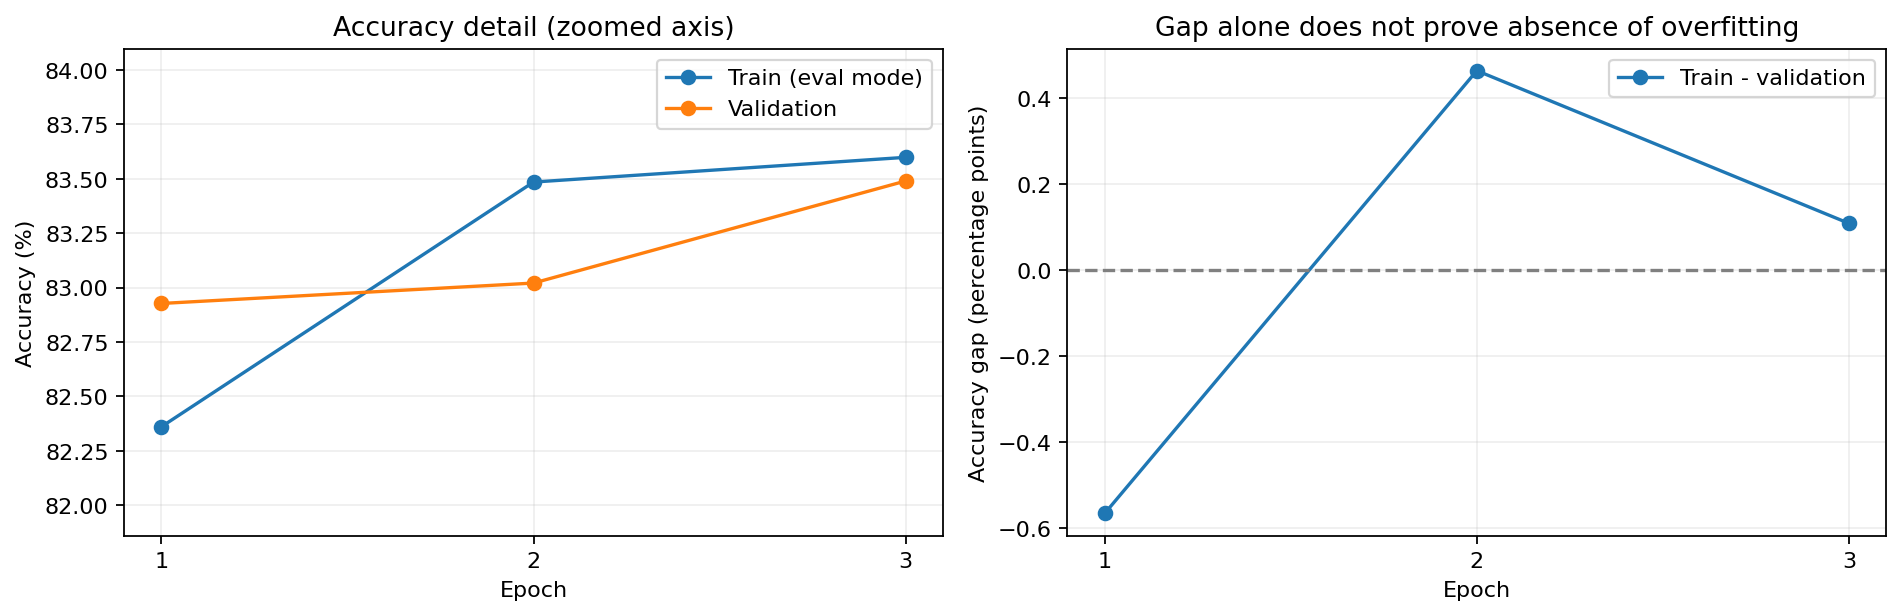

**data_quality.png**

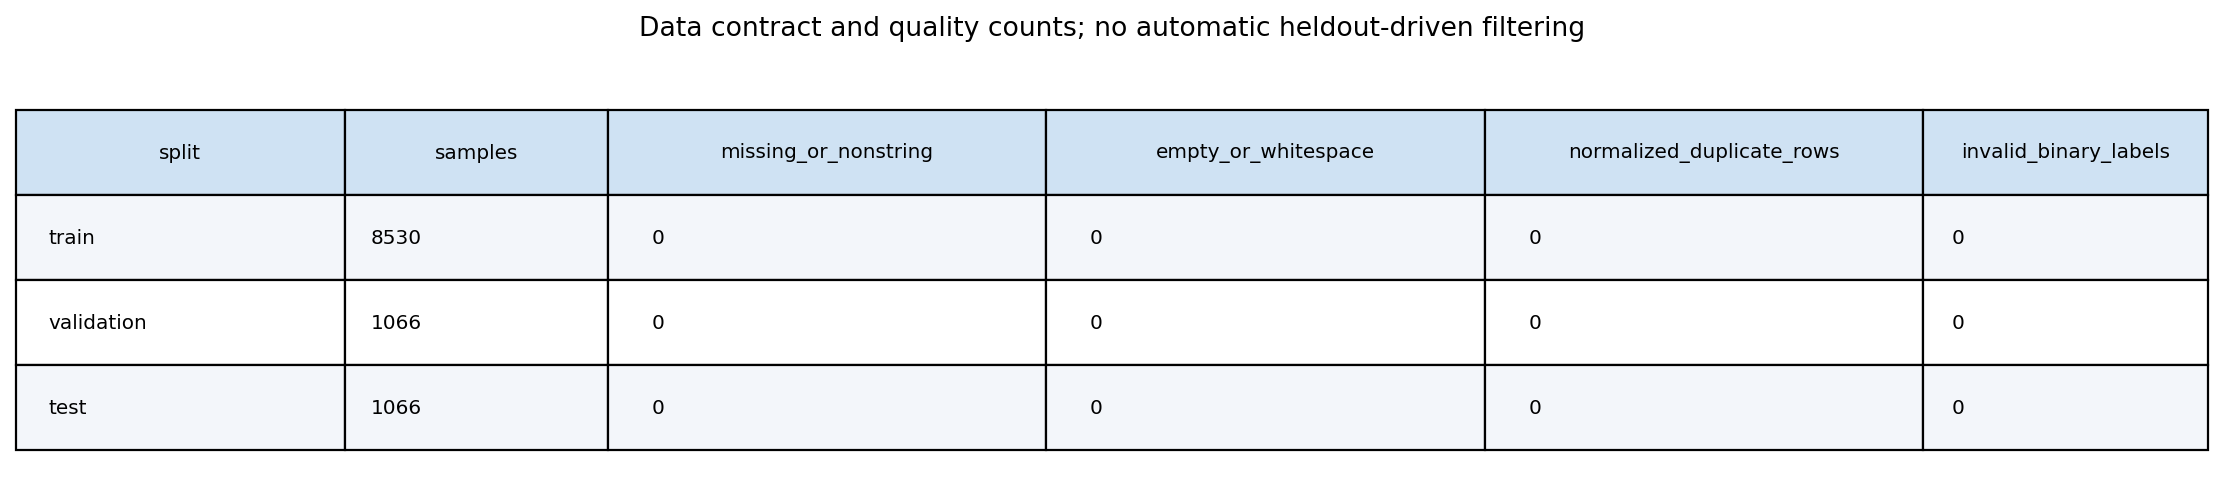

**lengths_by_class.png**

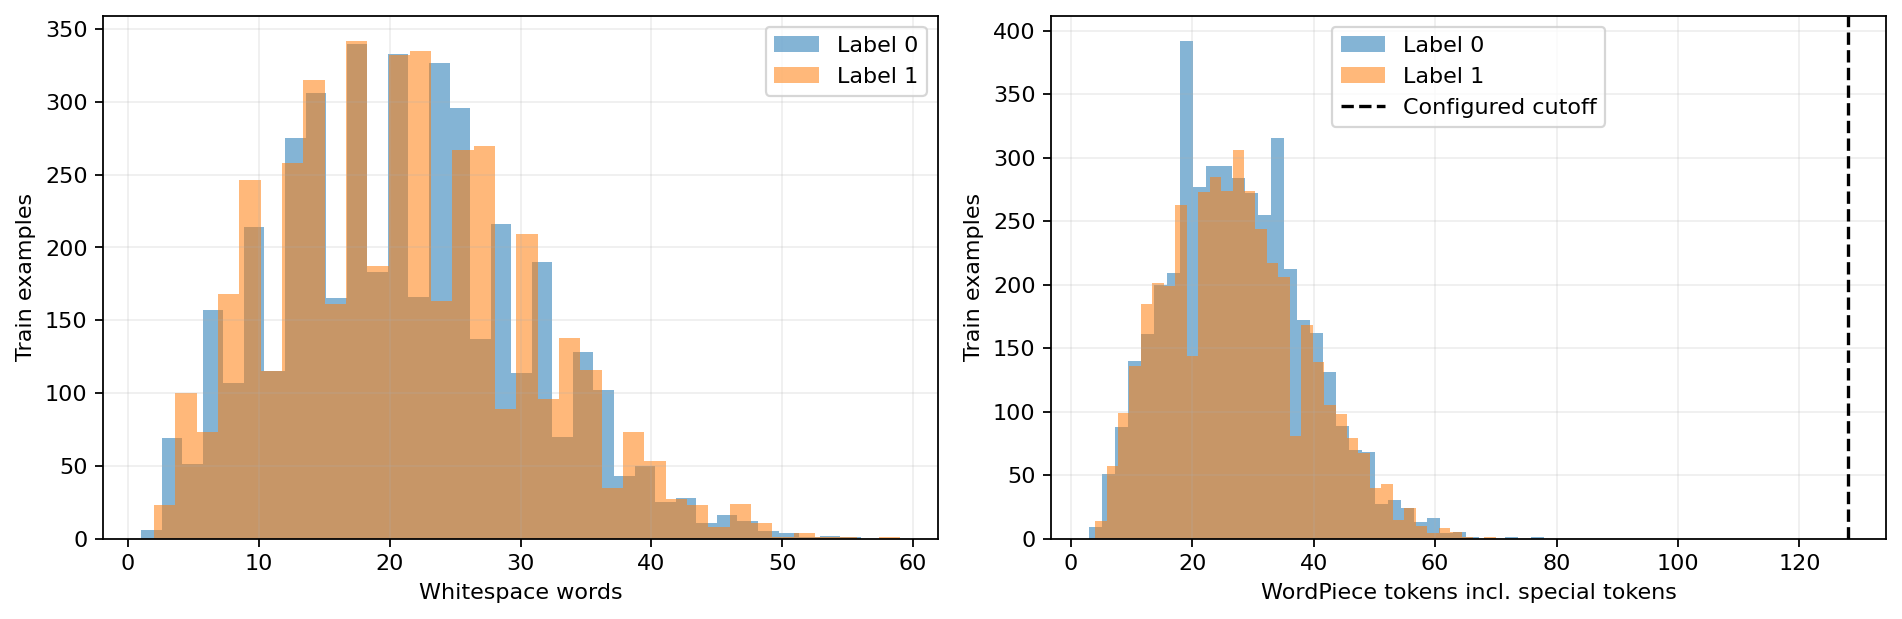

**augmentation_diagnostics.png**

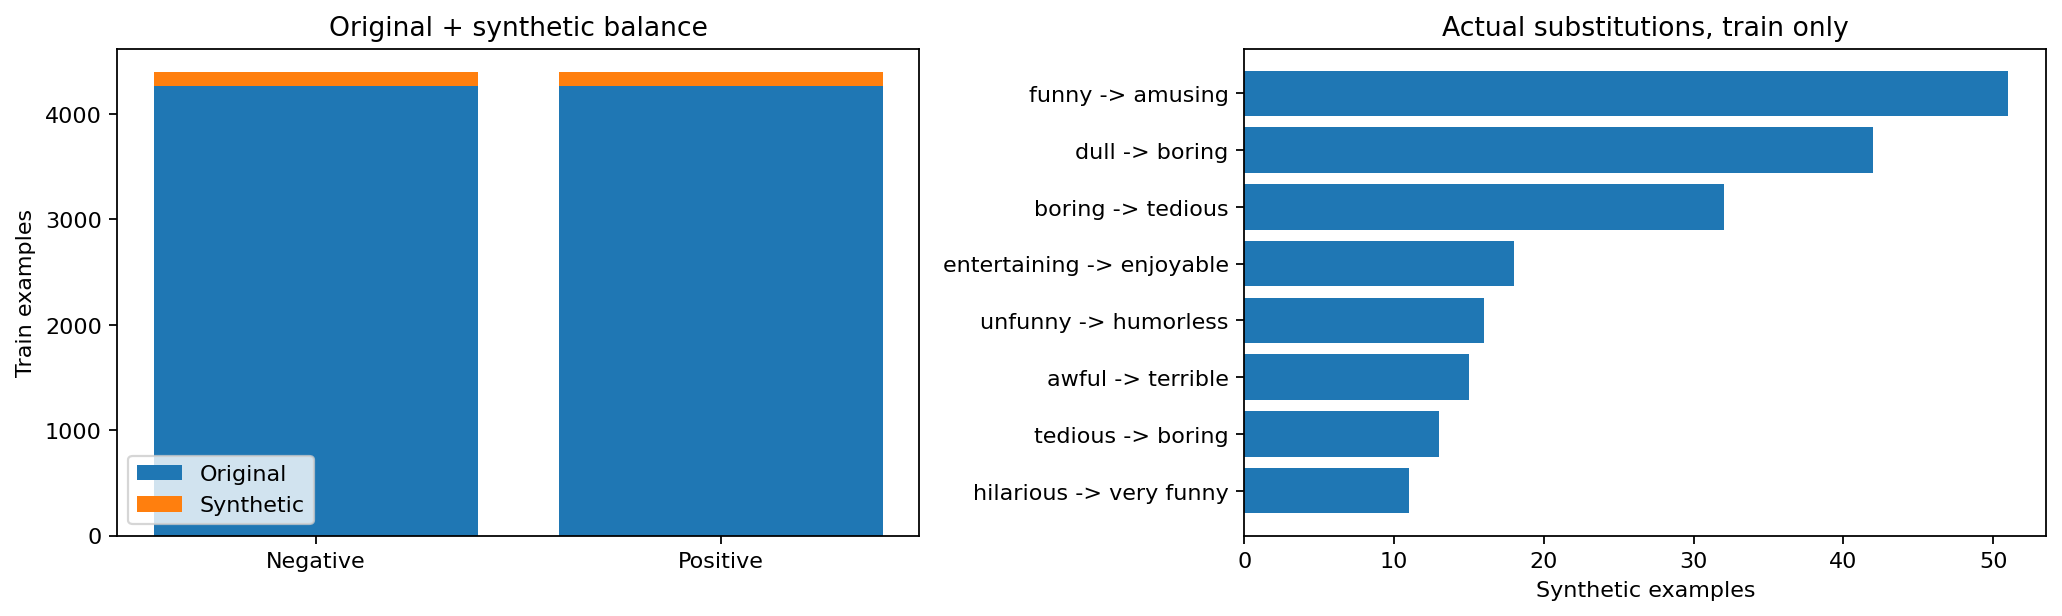

,C,accuracy,binary_precision,binary_recall,binary_f1,macro_precision,macro_recall,macro_f1,loss,selection_split,validation_probabilities,validation_labels
0,0.1,0.721388,0.713768,0.739212,0.726267,0.721670,0.721388,0.721300,0.645059,validation,"[[0.4506007391050416, 0.5493992608949584], [0....","[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ..."
1,1.0,0.753283,0.745455,0.769231,0.757156,0.753541,0.753283,0.753221,0.535465,validation,"[[0.3719048002424057, 0.6280951997575943], [0....","[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ..."
2,10.0,0.752345,0.745887,0.765478,0.755556,0.752519,0.752345,0.752302,0.487864,validation,"[[0.29514083605986663, 0.7048591639401334], [0...","[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, ..."


**augmentation_counts.png**

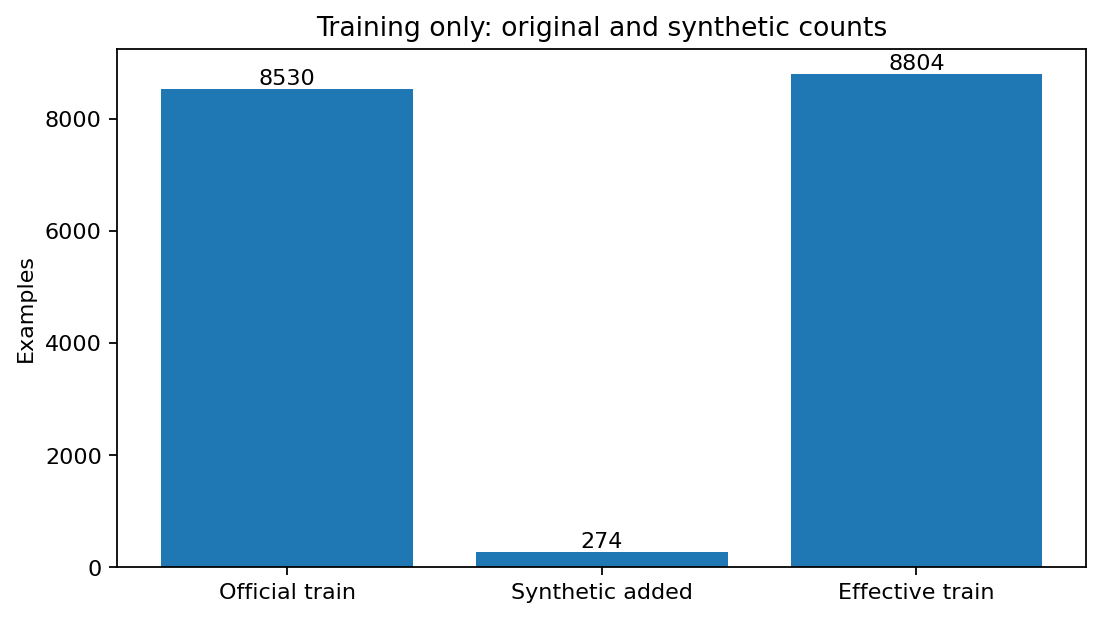

**augmentation_examples.png**

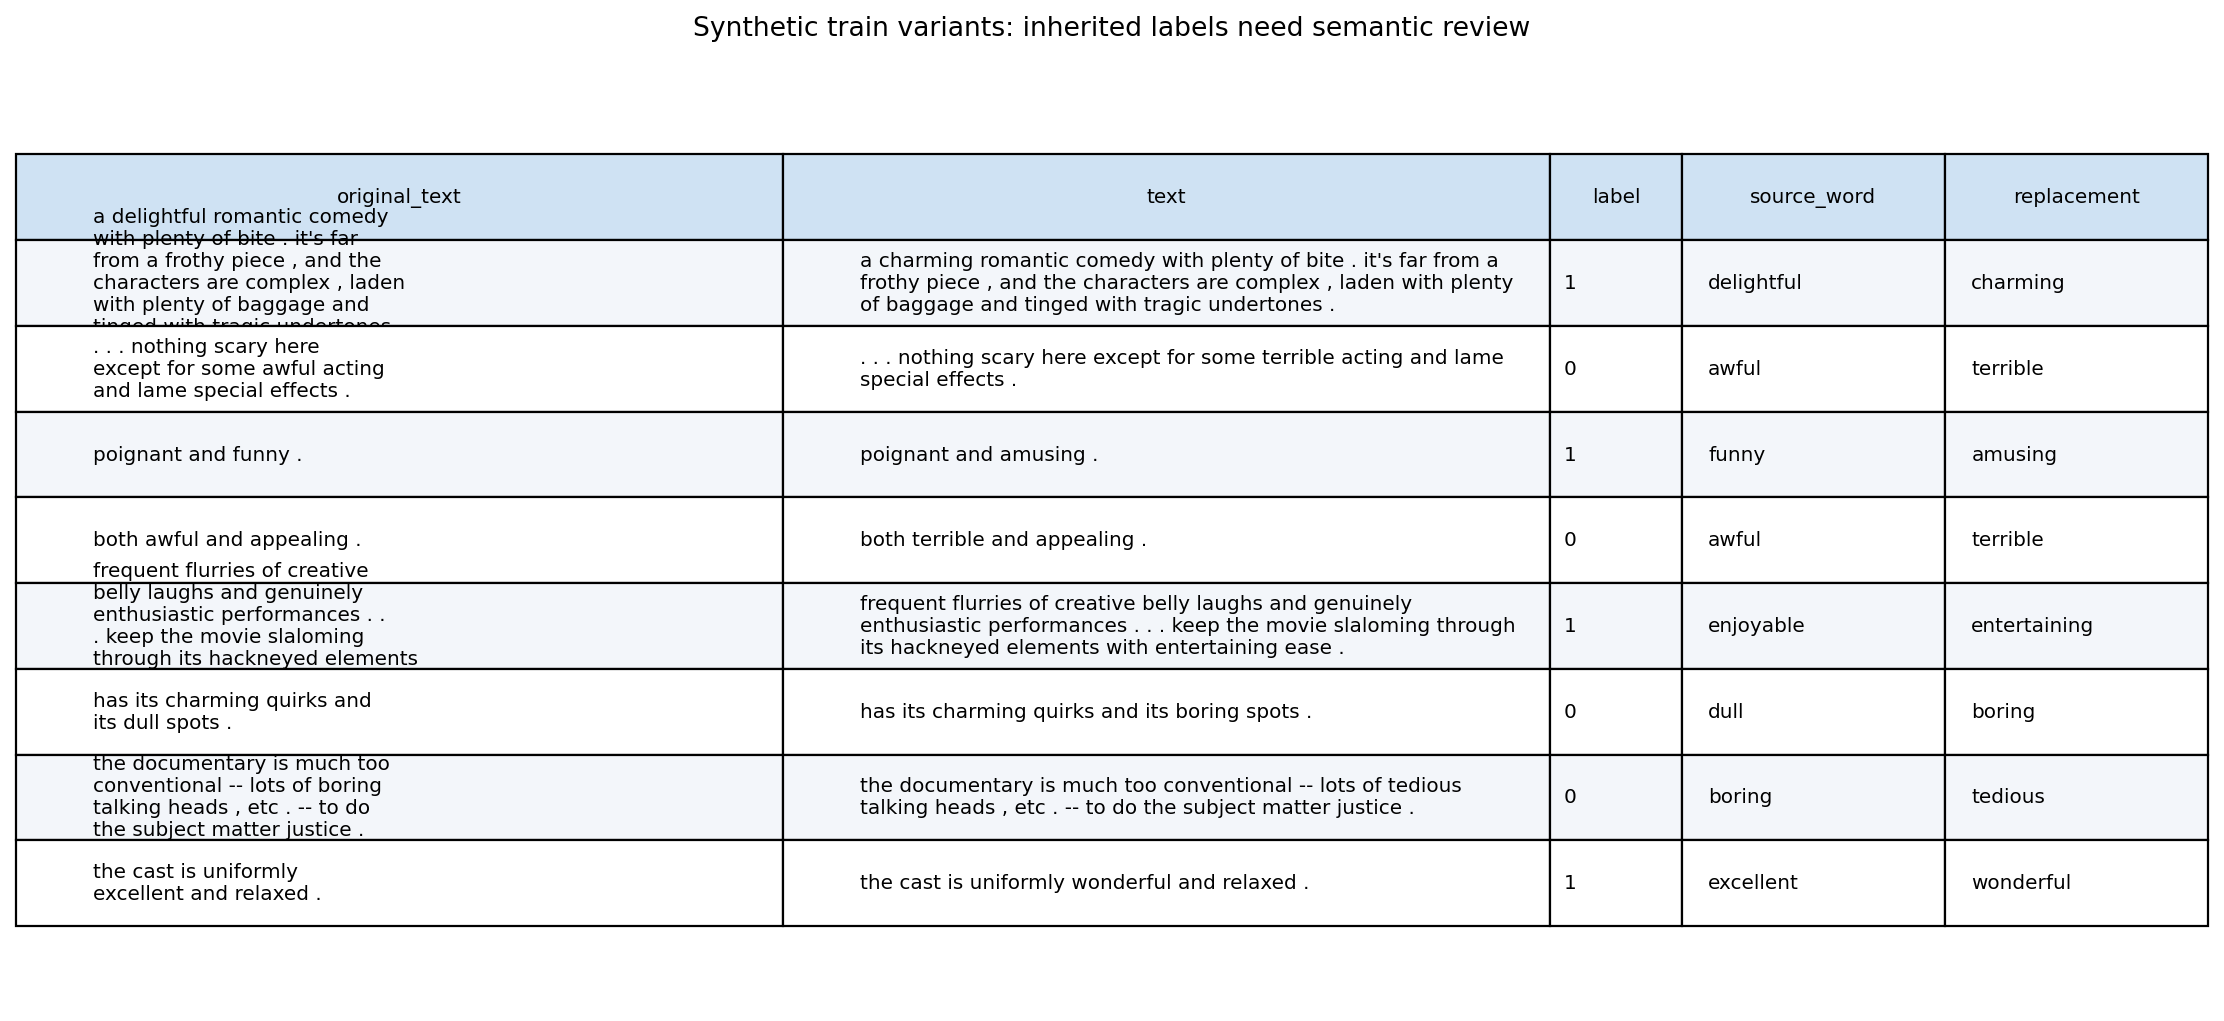

Fitted baseline pipeline (text):
Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_features=50000, min_df=2,
                                 ngram_range=(1, 2), sublinear_tf=True)),
                ('classifier',
                 LogisticRegression(max_iter=2000, random_state=42,
                                    solver='liblinear'))])


In [6]:
session.train()
print("Run:", session.paths["model"].name)
display(session.table("model", "epoch_history.json"))
session.show("model", ["learning_curves.png"])

session.paths["result_analysis"] = session.lab/"outputs/published/result_analysis"
results_summary = session.read(session.paths["result_analysis"]/"results_summary.json")
assert results_summary["source_run"] == session.paths["model"].name
session.show("result_analysis", ["learning_detail.png"])
session.show("model", ["data_quality.png", "lengths_by_class.png", "augmentation_diagnostics.png"])

display(session.table("model", "baseline_validation_candidates.json"))
session.show("model", ["augmentation_counts.png", "augmentation_examples.png"])

architecture_file = session.paths["model"]/"baseline_architecture.txt"
if architecture_file.is_file():
    print("Fitted baseline pipeline (text):")
    print(architecture_file.read_text(encoding="utf-8"))


### Đọc đường học

Train loss giảm nhưng validation loss tăng thường cho thấy mô hình ngày càng tự tin vào lỗi hoặc học chi tiết riêng của train. Accuracy không đổi vẫn có thể đi cùng loss tăng. Gap nhỏ chưa đủ chứng minh tốt: cũng có thể underfit, phải so mức validation performance và baseline.

Đọc completed_epochs/stopped_early và selected_epoch từ artifact. Không điền thêm điểm, không đổi log hoặc chọn hyperparameter theo test.

Biểu đồ accuracy chi tiết dùng trục phần trăm có zoom, được ghi rõ trên hình. Đồ thị gốc vẫn giữ để xem toàn thang đo; cả hai dùng cùng epoch_history, không làm trơn hay thay đổi dữ liệu.

## 5. Performance: accuracy/loss, time/sample, RAM–VRAM/sample

Bảng tách metric theo epoch khỏi tài nguyên. `train_ms_per_sample` đo train phase, không gồm end-epoch evaluation/save; epoch_pipeline có train + full train-eval +validation. Test timing là batch evaluation throughput, **không phải latency một request**.

RAM là parent-process RSS peak sampled20ms. VRAM là PyTorch allocated/reserved peak trên GPU được chọn. Peak chia nominal batch slots để biểu diễn bộ nhớ dùng chung theo batch, không phải bộ nhớ riêng của từng câu. Giá trị thiếu giữ null; CPU VRAM là N/A. Sơ đồ bên dưới đọc cấu trúc model.config đã ghi khi load model.

,epoch,train_accuracy,validation_accuracy,train_loss,validation_loss
0,1,0.823603,0.829268,0.390423,0.394246
1,2,0.834848,0.830206,0.372226,0.380126
2,3,0.835984,0.834897,0.369313,0.377385


,epoch,train_ms_per_sample,epoch_pipeline_ms_per_train_sample,ram_peak_rss_mib,ram_mib_per_batch_slot,vram_peak_allocated_mib,vram_peak_reserved_mib,vram_mib_per_batch_slot
0,1,1.823128,2.295660,1554.312500,97.144531,567.465332,638.0,35.466583
1,2,1.766139,2.245535,1732.785156,108.299072,567.465332,638.0,35.466583
2,3,1.824356,2.308352,1829.039062,114.314941,567.465332,638.0,35.466583


{'test_eval_ms_per_sample': 0.49624765478424016,
 'test_eval_timing_scope': 'Trainer.predict full test, includes batching/transfer/evaluation overhead; not single-request latency',
 'memory_status': 'measured',
 'source_device': 'Tesla T4'}

**performance.png**

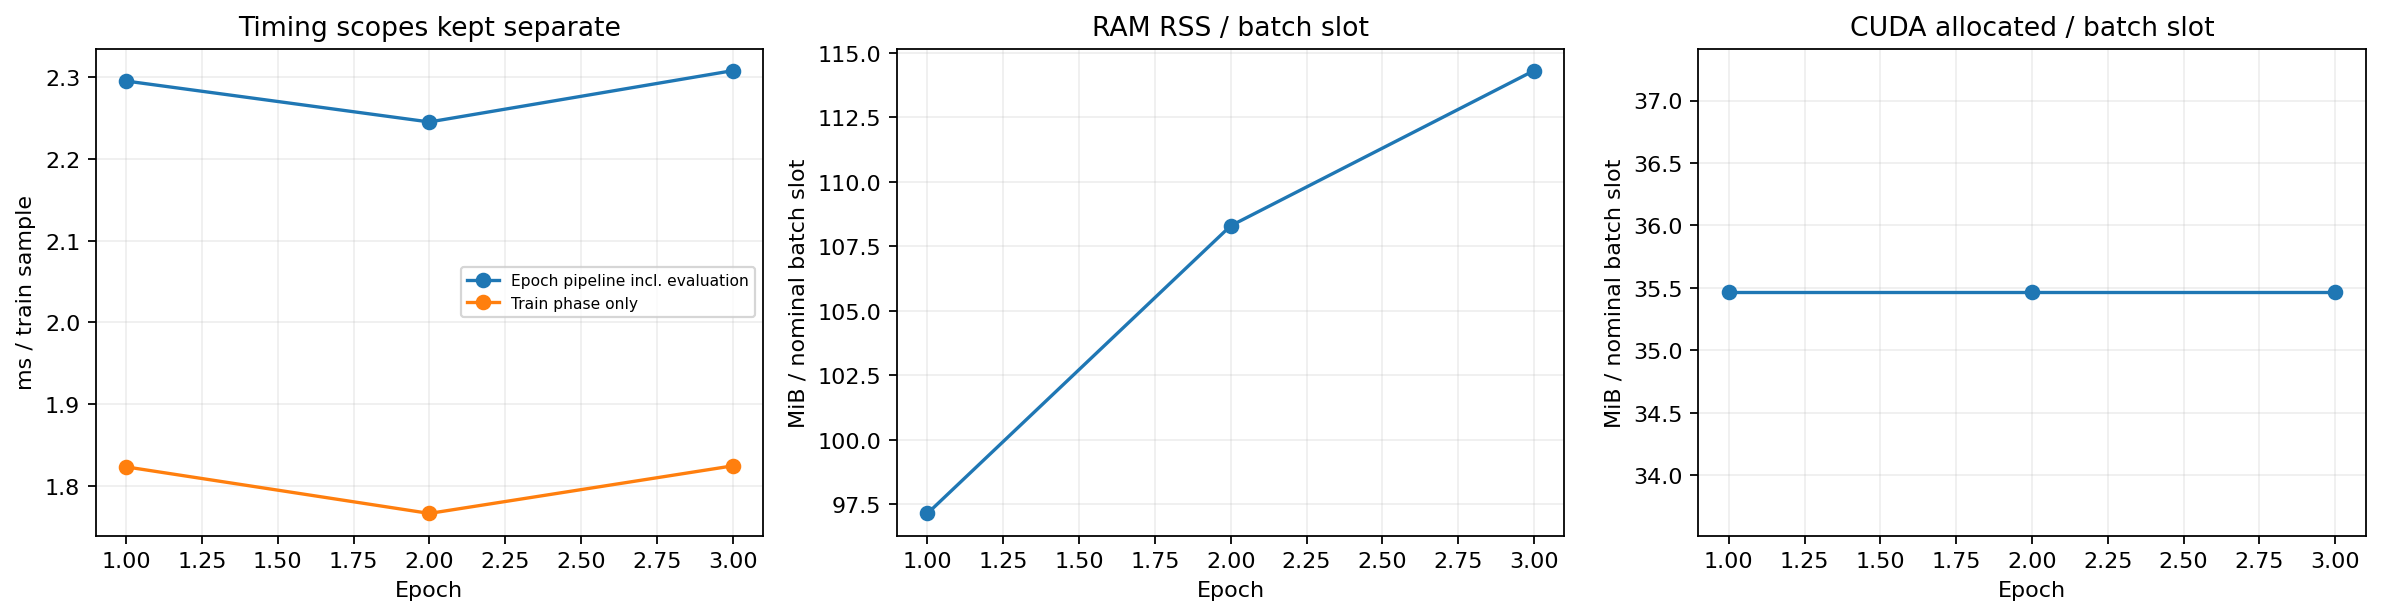

[PosixPath('/workspace/Lab-DL-new-lab03/labs/new-lab03/outputs/runs/20261104T110654Z_frozen_trial_00eccdd1/performance.png')]

In [7]:
performance = session.performance()
perf_table = session.table("performance", "performance_history.json")
display(perf_table[["epoch", "train_accuracy", "validation_accuracy", "train_loss", "validation_loss"]])
display(perf_table[["epoch", "train_ms_per_sample", "epoch_pipeline_ms_per_train_sample",
                    "ram_peak_rss_mib", "ram_mib_per_batch_slot", "vram_peak_allocated_mib",
                    "vram_peak_reserved_mib", "vram_mib_per_batch_slot"]])
display({k:performance[k] for k in ["test_eval_ms_per_sample", "test_eval_timing_scope", "memory_status", "source_device"]})
session.show("performance", ["performance.png"])


## 6. Chọn checkpoint và quét threshold trên validation

Sau khi reload checkpoint min validation loss, quét19thresholds0.05–0.95 bước0.05 bằng validation Macro-F1. Hòa điểm thì chọn gần0.5 hơn, tiếp đến threshold nhỏ hơn. Chốt policy và hash weights trước khi test; không ép threshold khác0.5.

Precision/recall thường đánh đổi khi threshold tăng. Grid và tie-break đã định trước; không mở rộng grid chỉ vì nhìn thấy test result.

Bảng patience bên dưới được tái hiện từ config/epoch history theo callback Transformers4.48.3, không phải counter được ghi trực tiếp. Counter có thể đạt patience đúng epoch cuối cùng trong ngân sách; stopped_early=False chỉ có nghĩa không dừng trước ngân sách.

,requested_epochs,completed_epochs,early_stopping,stopped_early,early_stopping_settings,checkpoint_selection_metric,selected_epoch,best_step,best_validation_loss,global_step,amp_skipped_optimizer_steps,test_used_for_selection
0,3,3.0,True,False,"{'enabled': True, 'patience': 2, 'min_delta': ...",validation_loss,3,1653,0.377385,1653,2,False


{'threshold': 0.5,
 'accuracy': 0.8348968105065666,
 'precision': 0.8426103646833013,
 'recall': 0.8236397748592871,
 'specificity': 0.8461538461538461,
 'FPR': 0.15384615384615385,
 'binary_f1': 0.8330170777988615,
 'macro_f1': 0.8348758858382063,
 'TN': 451,
 'FP': 82,
 'FN': 94,
 'TP': 439,
 'negative_support': 533,
 'positive_support': 533,
 'sample_count': 1066}

,threshold,accuracy,precision,recall,specificity,FPR,binary_f1,macro_f1,TN,FP,FN,TP,negative_support,positive_support,sample_count
0,0.05,0.594747,0.552440,0.998124,0.191370,0.808630,0.711230,0.515992,102,431,1,532,533,533,1066
1,0.10,0.705441,0.633700,0.973734,0.437148,0.562852,0.767751,0.682594,233,300,14,519,533,533,1066
2,0.15,0.751407,0.678667,0.954972,0.547842,0.452158,0.793453,0.740660,292,241,24,509,533,533,1066
3,0.20,0.791745,0.727007,0.934334,0.649156,0.350844,0.817734,0.787423,346,187,35,498,533,533,1066
4,0.25,0.809568,0.757009,0.911820,0.707317,0.292683,0.827234,0.807556,377,156,47,486,533,533,1066
5,0.30,0.819887,0.776337,0.898687,0.741088,0.258912,0.833043,0.818762,395,138,54,479,533,533,1066
6,0.35,0.828330,0.796610,0.881801,0.774859,0.225141,0.837044,0.827838,413,120,63,470,533,533,1066
7,0.40,0.832083,0.811620,0.864916,0.799250,0.200750,0.837421,0.831901,426,107,72,461,533,533,1066
8,0.45,0.828330,0.824074,0.834897,0.821764,0.178236,0.829450,0.828323,438,95,88,445,533,533,1066
9,0.50,0.834897,0.842610,0.823640,0.846154,0.153846,0.833017,0.834876,451,82,94,439,533,533,1066


**validation_threshold_curves.png**

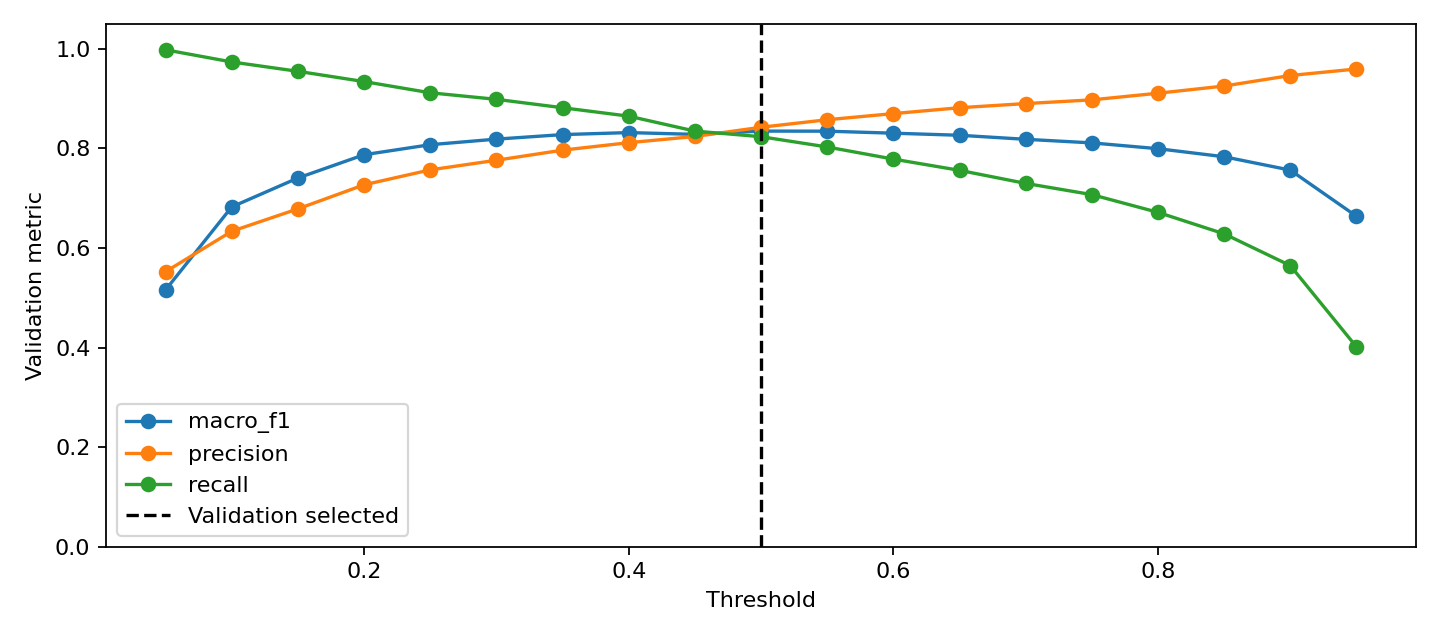

Validation-selected threshold: 0.5


,epoch,validation_loss,previous_best_loss,improved_beyond_min_delta,patience_counter
0,1,0.394246,NaN,True,0
1,2,0.380126,0.394246,True,0
2,3,0.377385,0.380126,True,0


In [8]:
display(session.table("model", "selection_summary.json"))
policy = session.read(session.paths["model"]/"decision_threshold.json")
display(policy["selected_metrics"])
display(session.table("model", "validation_threshold_scan.json"))
session.show("model", ["validation_threshold_curves.png"])

print("Validation-selected threshold:", policy["selected_threshold"])

session.paths["result_analysis"] = session.lab/"outputs/published/result_analysis"
results_summary = session.read(session.paths["result_analysis"]/"results_summary.json")
assert results_summary["source_run"] == session.paths["model"].name, "Published analysis phải thuộc đúng model run."
display(session.table("result_analysis", "early_stopping_replay.json", "epochs"))


## 7. Đánh giá test và baseline

Áp dụng policy đã khóa cho toàn1.066test samples. So baseline, Transformer threshold0.5 và Transformer validation-selected threshold. Báo Accuracy, precision, recall, Binary/Macro-F1 và test loss; đọc confusion counts +row-normalized rates. So sánh này là của một lượt/seed, không mặc định Transformer luôn hơn baseline.

Precision/recall/F1/TPR/FPR báo riêng Negative và Positive. Baseline log loss tính lại từ saved probabilities; Transformer loss là số đo trong test_runtime_metrics. Metrics trong test_runtime_metrics dùng argmax, còn policy được chọn dùng threshold validation; test_comparison giữ rõ hai operating points.

,model,threshold,accuracy,precision,recall,specificity,FPR,binary_f1,macro_f1,TN,FP,FN,TP,negative_support,positive_support,sample_count
0,TF-IDF,0.5,0.789869,0.792060,0.786116,0.793621,0.206379,0.789077,0.789866,423,110,114,419,533,533,1066
1,Frozen DistilBERT threshold 0.5,0.5,0.821764,0.824197,0.818011,0.825516,0.174484,0.821092,0.821761,440,93,97,436,533,533,1066
2,Frozen DistilBERT validation threshold,0.5,0.821764,0.824197,0.818011,0.825516,0.174484,0.821092,0.821761,440,93,97,436,533,533,1066


,test_loss,test_accuracy,test_binary_precision,test_binary_recall,test_binary_f1,test_macro_precision,test_macro_recall,test_macro_f1,test_runtime,test_samples_per_second,test_steps_per_second
0,0.41451,0.821764,0.824197,0.818011,0.821092,0.821782,0.821764,0.821761,0.529,2015.249,64.276


**metrics_bar.png**

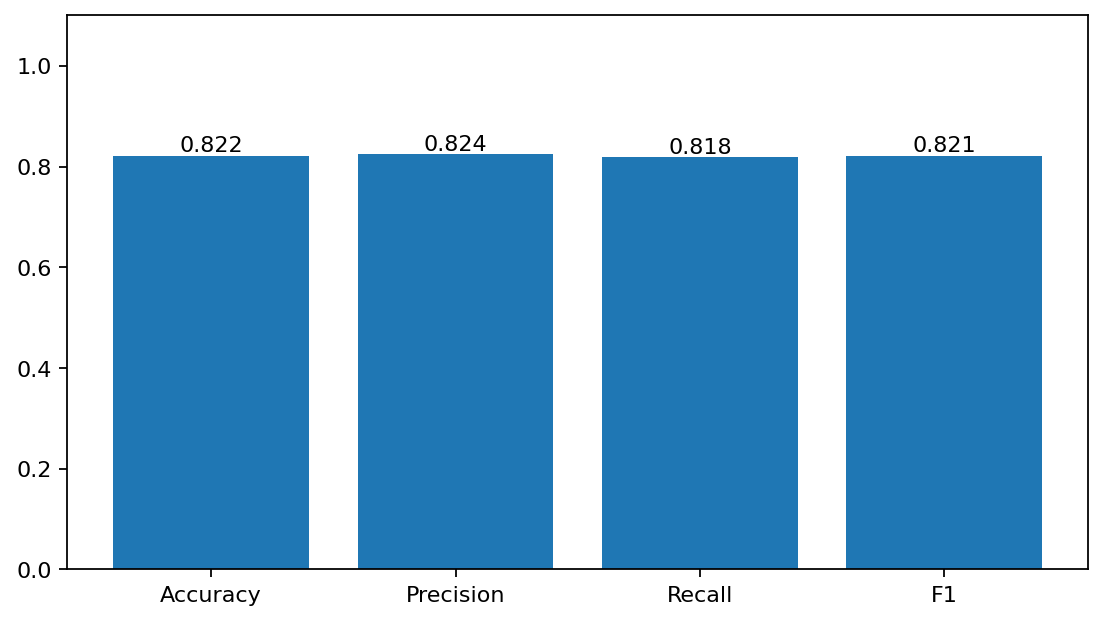

**confusion_matrix.png**

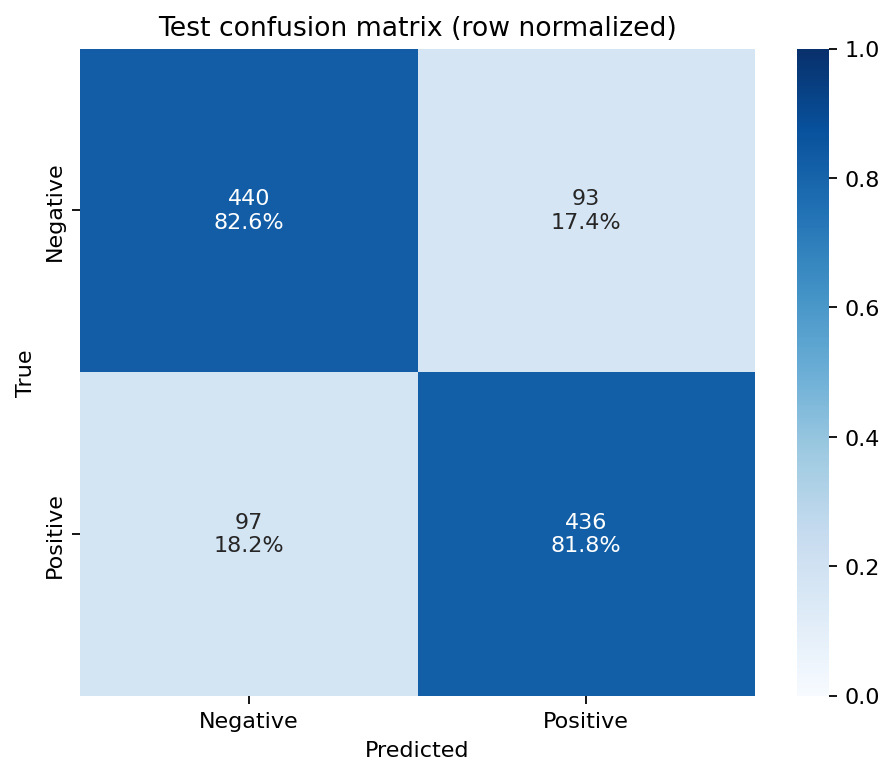

,label,class,precision,recall,f1,true_positive_rate,false_positive_rate,support,TP,FP,FN,TN
0,0,Negative,0.819367,0.825516,0.822430,0.825516,0.181989,533,440,97,93,436
1,1,Positive,0.824197,0.818011,0.821092,0.818011,0.174484,533,436,93,97,440


**per_class_metrics.png**

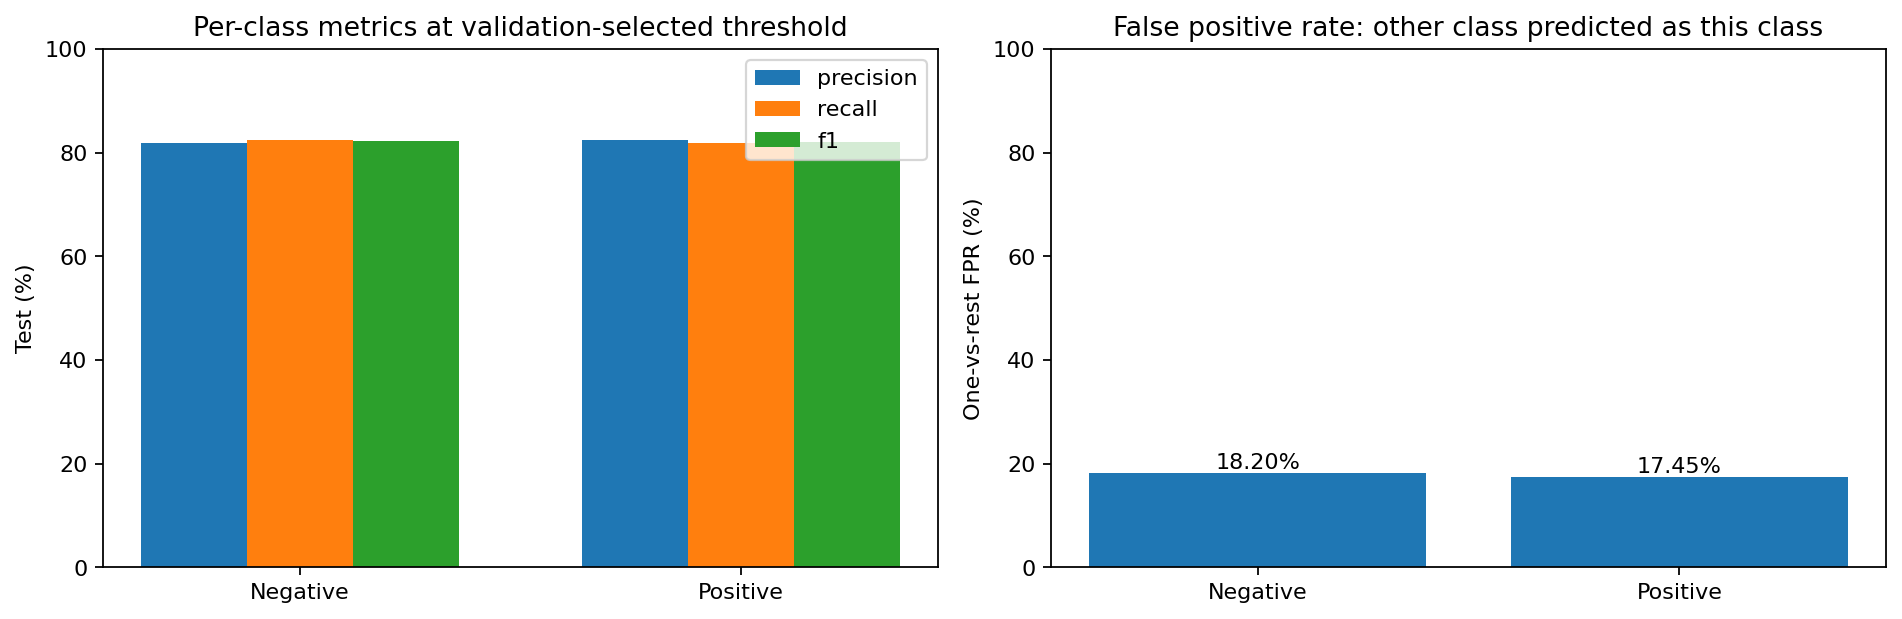

{'baseline_log_loss_recomputed': 0.5173709105267964,
 'transformer_test_loss_measured': 0.41450971364974976}

In [9]:
display(session.table("model", "test_comparison.json"))
display(session.table("model", "test_runtime_metrics.json"))
session.show("model", ["metrics_bar.png", "confusion_matrix.png"])

display(session.table("result_analysis", "per_class_metrics.json"))
session.show("result_analysis", ["per_class_metrics.png"])
display({"baseline_log_loss_recomputed": results_summary["baseline_log_loss"],
         "transformer_test_loss_measured": results_summary["test_loss"]})


### ROC/PR, calibration và uncertainty

ROC/PR khảo sát score ranking; reliability diagram, Brier và ECE khảo sát chất lượng confidence. Chúng là diagnostics sau khi khóa policy, không dùng test chọn threshold. Bootstrap interval chỉ mô tả fixed-model/test sampling, không bao gồm training-seed uncertainty. Accuracy cao vẫn có thể đi cùng confidence kém hoặc false positives/negatives mất cân đối.

,roc_auc,average_precision,brier_score,confidence_ece,nll,threshold,selection_split,bootstrap_95_percentile_ci,bootstrap_repeats,ci_scope
0,0.895716,0.903909,0.129814,0.032026,0.414515,0.5,validation,"{'accuracy': [0.799249530956848, 0.84427767354...",2000,"fixed model, fixed threshold, stratified test ..."


**roc_pr_curves.png**

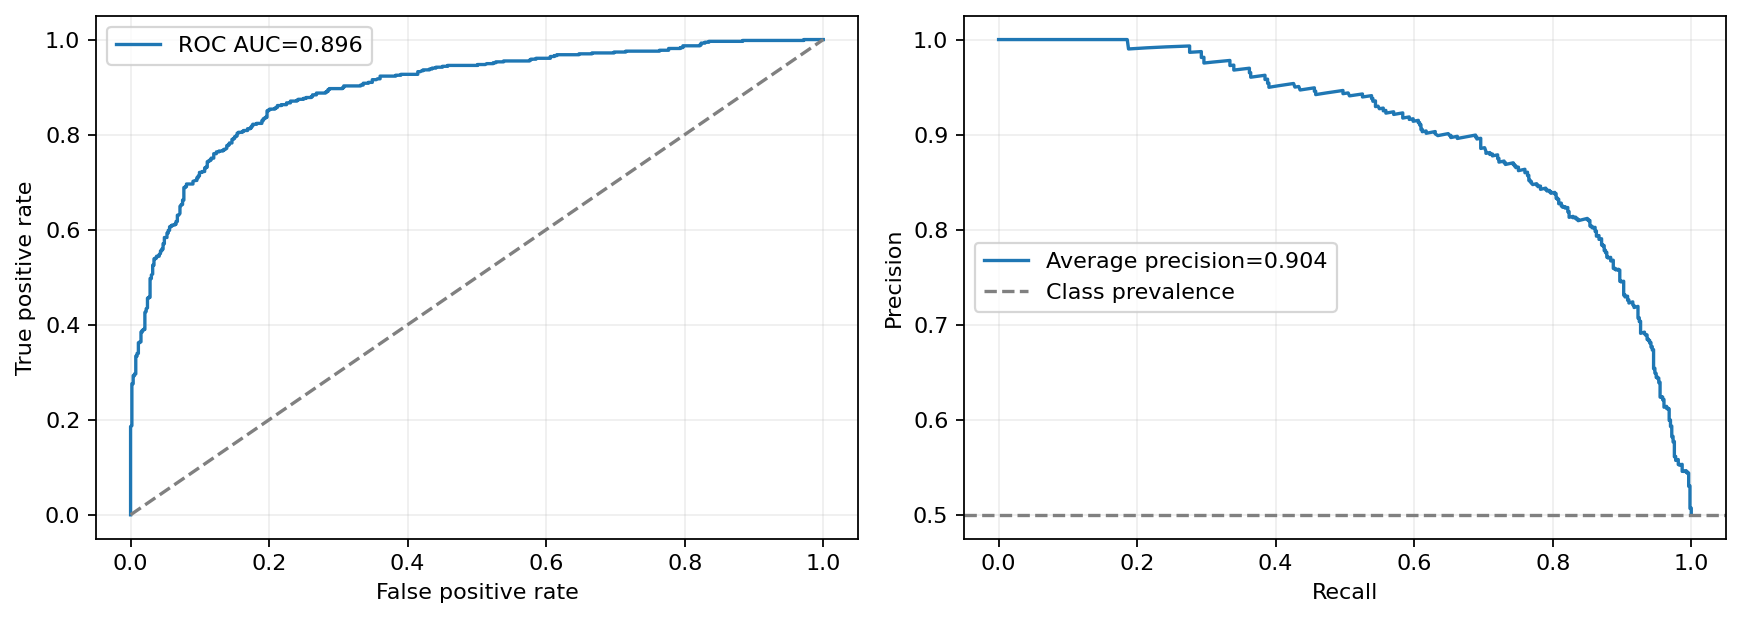

**calibration_confidence.png**

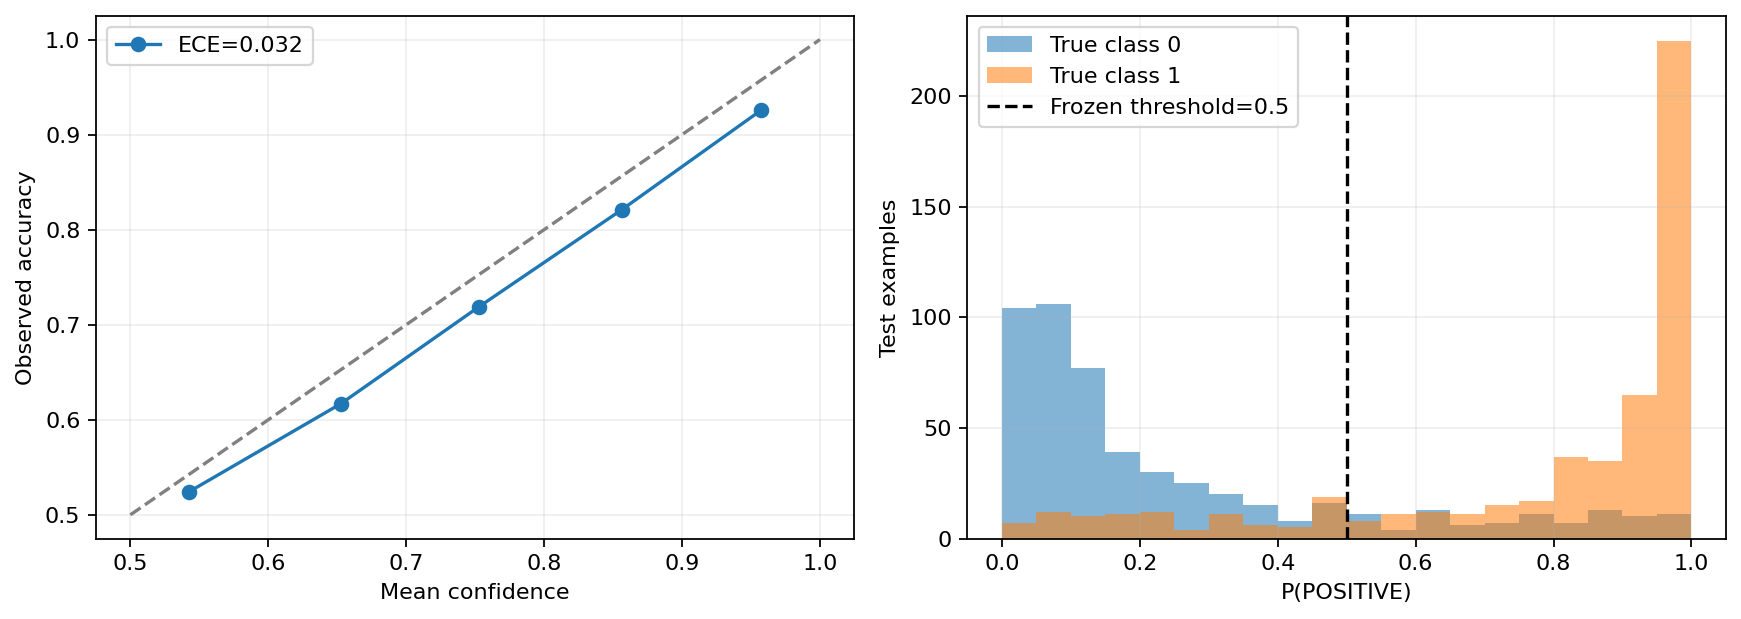

[PosixPath('/workspace/Lab-DL-new-lab03/labs/new-lab03/outputs/runs/20261104T110654Z_frozen_trial_00eccdd1/roc_pr_curves.png'),
 PosixPath('/workspace/Lab-DL-new-lab03/labs/new-lab03/outputs/runs/20261104T110654Z_frozen_trial_00eccdd1/calibration_confidence.png')]

In [10]:
display(session.table("model", "probability_diagnostics.json"))
session.show("model", ["roc_pr_curves.png", "calibration_confidence.png"])


## 8. Phân tích lỗi định tính

Đọc câu đúng/sai, nhãn thật, nhãn dự đoán và confidence; chú ý phủ định, tương phản, châm biếm và implicit sentiment. Bảng lấy high-confidence examples theo nhóm đúng/sai và lớp nên **không phải mẫu ngẫu nhiên đại diện toàn test**. Giải thích ngôn ngữ là giả thuyết, không phải causal attribution.

`threshold_errors` lưu các câu sai dưới policy đã chọn. Đọc trade-off FP/FN trong test_comparison thay vì chỉ một metric tổng.

**sample_predictions.png**

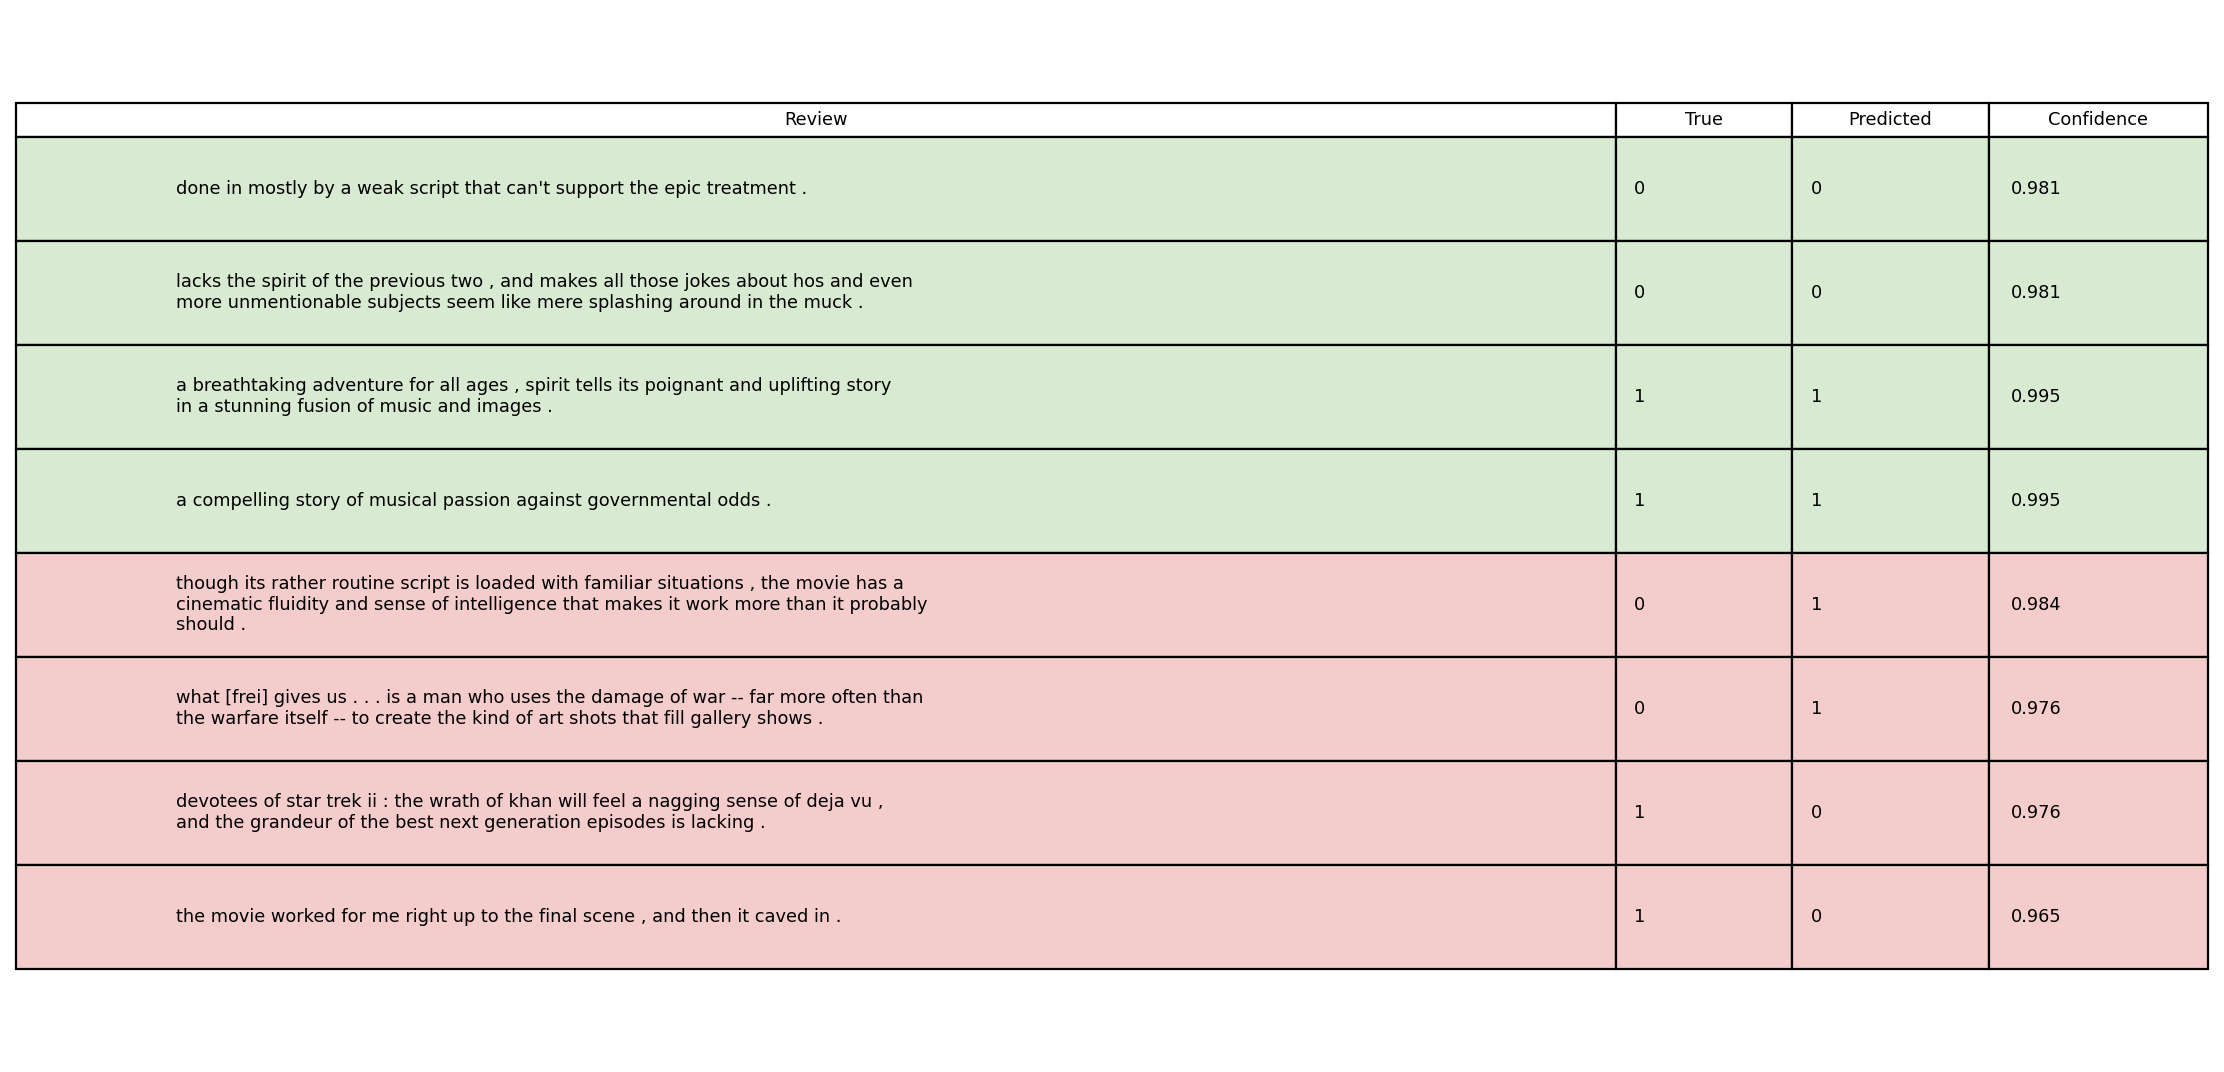

,index,true_label,predicted_label,positive_probability,decision_confidence,text
0,2,1,0,0.198142,0.801858,"it's like a "" big chill "" reunion of the baade..."
1,4,1,0,0.162181,0.837819,"red dragon "" never cuts corners ."
2,11,1,0,0.466679,0.533321,it's up to you to decide whether to admire the...
3,12,1,0,0.220342,0.779658,"mostly , [goldbacher] just lets her complicate..."
4,14,1,0,0.045016,0.954984,"at its worst , the movie is pretty diverting ;..."
5,22,1,0,0.480383,0.519617,grown-up quibbles are beside the point here . ...
6,24,1,0,0.179028,0.820972,this is a fascinating film because there is no...
7,25,1,0,0.477889,0.522111,a dreadful day in irish history is given passi...
8,28,1,0,0.023803,0.976197,devotees of star trek ii : the wrath of khan w...
9,30,1,0,0.371450,0.628550,what's so striking about jolie's performance i...


,index,text,true_label,probabilities
0,0,lovingly photographed in the manner of a golde...,1,"[0.1652560532093048, 0.8347439169883728]"
1,1,consistently clever and suspenseful .,1,"[0.017712296918034554, 0.9822876453399658]"
2,2,"it's like a "" big chill "" reunion of the baade...",1,"[0.8018582463264465, 0.19814173877239227]"
3,3,the story gives ample opportunity for large-sc...,1,"[0.013121270574629307, 0.9868786931037903]"
4,4,"red dragon "" never cuts corners .",1,"[0.8378190398216248, 0.16218088567256927]"
5,5,fresnadillo has something serious to say about...,1,"[0.30347371101379395, 0.696526288986206]"
6,6,throws in enough clever and unexpected twists ...,1,"[0.043446898460388184, 0.9565531015396118]"
7,7,weighty and ponderous but every bit as filling...,1,"[0.3368762135505676, 0.6631237864494324]"


In [11]:
session.show("model", ["sample_predictions.png"])
display(session.table("model", "threshold_errors.json").head(12))
display(session.table("model", "test_predictions.json").head(8))


## 9. Save/load, publish và tải artifact

Save model/tokenizer/policy, reload và so logits trên validation trong tolerance. Mỗi run lưu config, source hashes, environment, log, predictions, PNG/JSON và SHA256 manifest. Mỗi hình hiển thị trong notebook là cùng file PNG lưu trên disk.

Kết thúc training tự publish hình/bảng/log vào `outputs/published/`, nguồn ở `outputs/latest_report.json`. **Review ZIP** chứa artifact nhẹ/manifest/log; **checkpoint ZIP** riêng chứa weights để reload/evaluate/infer. Giữ checkpoint riêng, không đưa weights/ZIP lên Git.

Tải notebook của phiên Kaggle qua File → Download Notebook nếu cần lưu cell outputs; interactive notebook không tự nằm trên disk của training container.

In [12]:
reload_check = session.read(session.paths["model"]/"reload_check.json")
display({k:v for k,v in reload_check.items() if k != "predictions"})
print("Published report:", session.lab/"outputs/published/index.md")
session.export()


{'weights_exact_match': True, 'execution': 'CPU FP32, clean forward methods'}

Published report: /workspace/Lab-DL-new-lab03/labs/new-lab03/outputs/published/index.md
Artifact report: /workspace/Lab-DL-new-lab03/labs/new-lab03/outputs/published/index.md


### Câu hỏi bảo vệ

- Vì sao pretrained base thay vì học Transformer từ đầu? Tận dụng biểu diễn ngôn ngữ và giảm nhu cầu dữ liệu/compute.
- Vì sao có baseline? Để kiểm tra lợi ích thực tế của mô hình phức tạp.
- Freeze có tắt dropout không? Không; requires_grad=False ngăn cập nhật weights, eval mode mới tắt dropout.
- Early stopping với budget3/patience2 hoạt động thế nào? Đánh giá mỗi epoch nên sớm nhất có thể đạt patience ở epoch3; vẫn reload checkpoint minimum validation loss.
- Vì sao validation loss dùng chọn checkpoint còn Macro-F1 dùng threshold? Hai bước tối ưu hai quyết định khác nhau, cùng chỉ dùng validation.
- Có bảo đảm không overfit không? Không; báo mức gap, calibration và giới hạn dữ liệu/seed.
- RAM/VRAM per batch slot có phải bộ nhớ riêng một câu không? Không; có shared model memory và phụ thuộc batch/dynamic padding.
- Lấy hình làm report có cần rerun không? Không, sau khi train thành công các hình/bảng/log đã publish.